# Resultados del modelo y figuras del reporte

Fases *Evaluation* y *Deployment* de CRISP-DM. Este notebook lee las salidas
de `kedro run` desde el Data Catalog, interpreta el modelo final
(Gradient Boosting) y guarda las figuras del reporte en `docs/figuras/`.

**Requisito:** ejecutar `kedro run` antes de este notebook.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from kedro.config import OmegaConfigLoader
from kedro.io import DataCatalog
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", message=".*register_new_resolver.*")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(raiz)
config = OmegaConfigLoader(conf_source="conf", base_env="base", default_run_env="local")
catalog = DataCatalog.from_config(config["catalog"])

CARPETA_FIGURAS = Path("docs/figuras")
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
AZUL, ROJO, GRIS = "#4C72B0", "#C44E52", "#8C8C8C"


def guardar(fig: plt.Figure, nombre: str) -> None:
    """Guarda una figura del reporte en docs/figuras."""
    fig.savefig(CARPETA_FIGURAS / f"{nombre}.png", dpi=200, bbox_inches="tight")

In [2]:
clientes = catalog.load("clientes_limpios")
comparacion = catalog.load("comparacion_modelos")
impacto = catalog.load("comparacion_impacto").set_index("estrategia")
modelo = catalog.load("modelo_gradient_boosting")
X_test = catalog.load("X_test")
y_test = catalog.load("y_test")

## 1. Dónde se concentra el churn

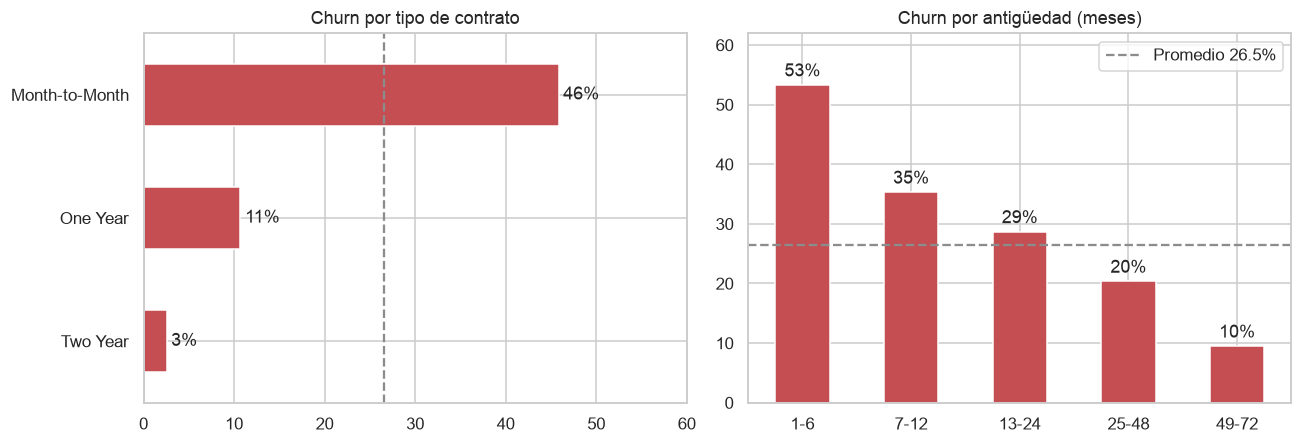

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
tasa_global = clientes["Churn Value"].mean() * 100

por_contrato = clientes.groupby("Contract")["Churn Value"].mean().mul(100).sort_values()
por_contrato.plot.barh(ax=axes[0], color=ROJO)
axes[0].bar_label(axes[0].containers[0], fmt="%.0f%%", padding=3)
axes[0].set_title("Churn por tipo de contrato")

rangos = pd.cut(
    clientes["Tenure in Months"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=["1-6", "7-12", "13-24", "25-48", "49-72"],
)
por_antiguedad = clientes.groupby(rangos, observed=True)["Churn Value"].mean() * 100
por_antiguedad.plot.bar(ax=axes[1], color=ROJO, rot=0, label="_nolegend_")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f%%", padding=3)
axes[1].set_title("Churn por antigüedad (meses)")
axes[1].set_xlabel("")

for ax in axes:
    ax.set_ylabel("")
axes[0].axvline(tasa_global, color=GRIS, linestyle="--", label="Promedio 26.5%")
axes[1].axhline(tasa_global, color=GRIS, linestyle="--", label="Promedio 26.5%")
axes[0].set_xlim(0, 60)
axes[1].set_ylim(0, 62)
axes[1].legend()
plt.tight_layout()
guardar(fig, "1_churn_contrato_antiguedad")
plt.show()

## 2. Comparación de modelos

Métricas en el conjunto de prueba (1,409 clientes que el modelo nunca vio).

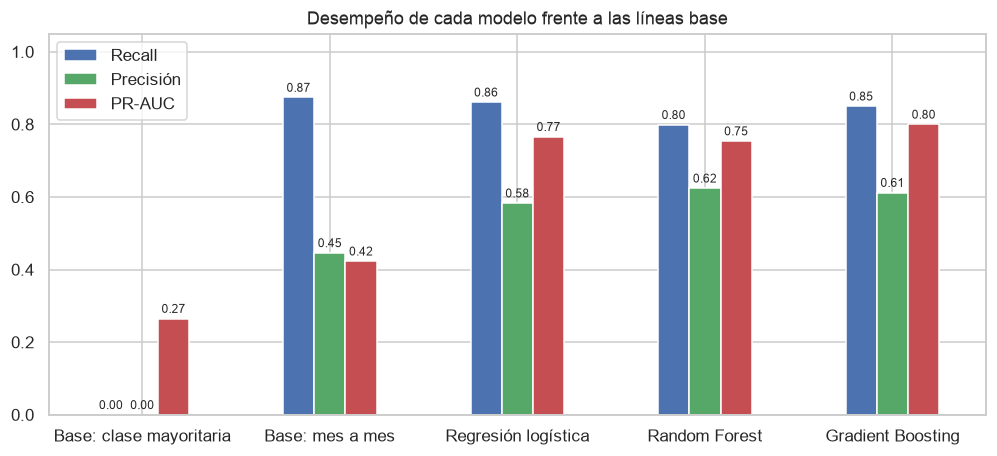

In [4]:
metricas = comparacion.set_index("modelo")[["recall", "precision", "pr_auc"]].rename(
    columns={"recall": "Recall", "precision": "Precisión", "pr_auc": "PR-AUC"},
    index=lambda m: m.replace("Línea base: ", "Base: ").replace(
        "Contract = Month-to-Month", "mes a mes"
    ),
)
ax = metricas.plot.bar(figsize=(11, 4.5), rot=0, color=[AZUL, "#55A868", ROJO])
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1.05)
ax.set_title("Desempeño de cada modelo frente a las líneas base")
ax.set_xlabel("")
ax.legend(loc="upper left")
guardar(ax.figure, "2_comparacion_modelos")
plt.show()

## 3. Impacto económico

Ahorro neto de una campaña que contacta a 2,000 clientes ($100,000), según
cómo se eligen los clientes.

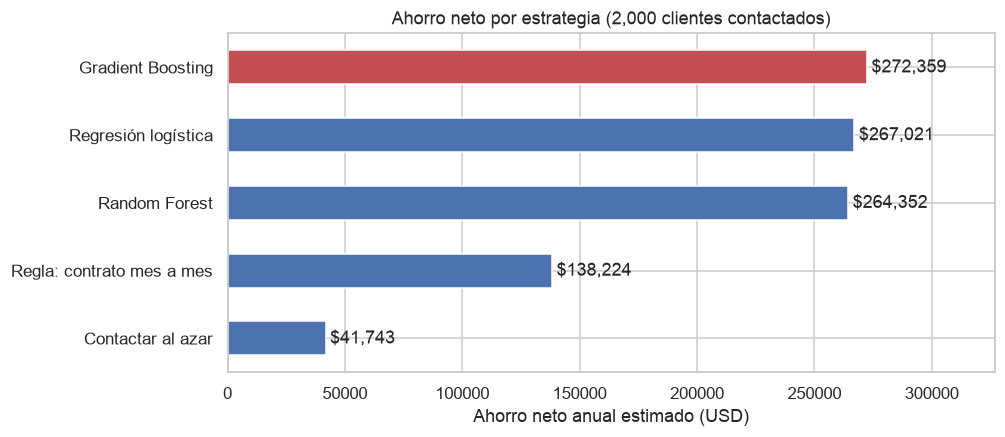

In [5]:
ahorro = (
    impacto["ahorro_neto"]
    .rename(
        index=lambda e: e.replace(
            "Regla: Contract = Month-to-Month", "Regla: contrato mes a mes"
        )
    )
    .sort_values()
)
colores = [ROJO if e == "Gradient Boosting" else AZUL for e in ahorro.index]

ax = ahorro.plot.barh(figsize=(9, 4), color=colores)
ax.bar_label(ax.containers[0], labels=[f"${v:,.0f}" for v in ahorro], padding=3)
ax.set_xlim(0, ahorro.max() * 1.2)
ax.set_xlabel("Ahorro neto anual estimado (USD)")
ax.set_ylabel("")
ax.set_title("Ahorro neto por estrategia (2,000 clientes contactados)")
guardar(ax.figure, "3_ahorro_neto")
plt.show()

In [6]:
impacto[["clientes_detectados", "clientes_retenidos", "ahorro_neto"]].round(0)

,clientes_detectados,clientes_retenidos,ahorro_neto
estrategia,,,
Contactar al azar,531.0,159.0,41743.0
Regla: Contract = Month-to-Month,892.0,268.0,138224.0
Regresión logística,1375.0,412.0,267021.0
Random Forest,1365.0,409.0,264352.0
Gradient Boosting,1395.0,418.0,272359.0


## 4. ¿Qué variables usa el modelo?

**Importancia por permutación:** se desordena una variable a la vez en el
conjunto de prueba y se mide cuánto cae la PR-AUC. Si el modelo empeora mucho,
esa variable es importante. Funciona con cualquier modelo y se calcula sobre
las variables originales (antes del *one-hot*), así que es fácil de explicar.

In [7]:
resultado = permutation_importance(
    modelo,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)
importancia = (
    pd.DataFrame(
        {
            "caida_pr_auc": resultado.importances_mean,
            "desviacion": resultado.importances_std,
        },
        index=X_test.columns,
    )
    .sort_values("caida_pr_auc", ascending=False)
    .round(4)
)
importancia.head(10)

,caida_pr_auc,desviacion
Contract,0.1866,0.0137
Number of Referrals,0.1029,0.0126
Tenure in Months,0.0435,0.0079
Age,0.0349,0.0069
Number of Dependents,0.0344,0.0062
Monthly Charge,0.0226,0.0040
Latitude,0.0210,0.0070
Married,0.0136,0.0040
Longitude,0.0116,0.0026
Internet Type,0.0091,0.0034


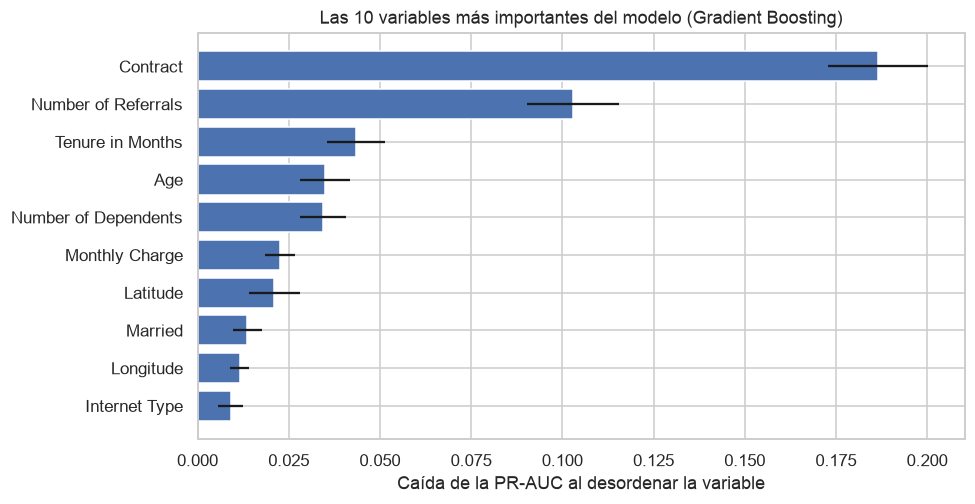

In [8]:
top = importancia.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top.index, top["caida_pr_auc"], xerr=top["desviacion"], color=AZUL)
ax.set_xlabel("Caída de la PR-AUC al desordenar la variable")
ax.set_title("Las 10 variables más importantes del modelo (Gradient Boosting)")
guardar(fig, "4_importancia_variables")
plt.show()

In [9]:
# Riesgo promedio que asigna el modelo según el valor de algunas variables
probabilidad = pd.Series(modelo.predict_proba(X_test)[:, 1], index=X_test.index)
grupos = {
    "Contrato mes a mes": X_test["Contract"] == "Month-to-Month",
    "Sin referidos": X_test["Number of Referrals"] == 0,
    "Cliente nuevo (≤ 6 meses)": X_test["cliente_nuevo"] == 1,
    "Sin dependientes": X_test["Number of Dependents"] == 0,
    "Fibra óptica": X_test["Internet Type"] == "Fiber Optic",
}
pd.DataFrame(
    {
        "riesgo_promedio_grupo": {g: probabilidad[m].mean() for g, m in grupos.items()},
        "riesgo_promedio_resto": {
            g: probabilidad[~m].mean() for g, m in grupos.items()
        },
    }
).mul(100).round(1)

,riesgo_promedio_grupo,riesgo_promedio_resto
Contrato mes a mes,60.5,12.0
Sin referidos,46.6,25.7
Cliente nuevo (≤ 6 meses),66.9,29.0
Sin dependientes,45.2,12.0
Fibra óptica,52.4,25.8


## Conclusiones

1. **Gradient Boosting** es el mejor modelo: PR-AUC 0.80, recall 0.85 y
   precisión 0.61 con el umbral de 0.5, y el mayor ahorro neto ($272,359 con
   2,000 contactos, 6.5 veces más que contactar al azar).
2. Las variables que más usa el modelo son el **tipo de contrato**, el
   **número de referidos**, la **antigüedad**, la **edad** y el **número de
   dependientes**. Esto respalda las recomendaciones de incentivar contratos
   anuales, acompañar a los clientes nuevos y fomentar el programa de referidos.
3. La importancia mide **asociación con el riesgo, no causalidad**: para saber
   si una acción reduce el churn hay que probarla con un grupo de control
   (A/B test).